In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [4]:
url = (
    "https://raw.githubusercontent.com/"
    "sismetanin/rureviews/master/"
    "women-clothing-accessories.3-class.balanced.csv"
)

df = pd.read_csv(url, sep="\t")

print("Размер датасета:", df.shape)
print("Названия столбцов:", df.columns.tolist())
print("\nРаспределение классов:")
print(df["sentiment"].value_counts())

display(df.head())

Размер датасета: (90000, 2)
Названия столбцов: ['review', 'sentiment']

Распределение классов:
sentiment
negative    30000
neautral    30000
positive    30000
Name: count, dtype: int64


,review,sentiment
0,качество плохое пошив ужасный (горловина напер...,negative
1,"Товар отдали другому человеку, я не получила п...",negative
2,"Ужасная синтетика! Тонкая, ничего общего с пре...",negative
3,"товар не пришел, продавец продлил защиту без м...",negative
4,"Кофточка голая синтетика, носить не возможно.",negative


In [5]:
df = df[["review", "sentiment"]].copy()
df.columns = ["text", "label"]

df = df.dropna()
df["text"] = df["text"].astype(str)
df = df.drop_duplicates(subset=["text"])

print("Количество документов:", len(df))
print("\nРаспределение классов:")
print(df["label"].value_counts())

display(df.head())

Количество документов: 87321

Распределение классов:
label
positive    29291
negative    29218
neautral    28812
Name: count, dtype: int64


,text,label
0,качество плохое пошив ужасный (горловина напер...,negative
1,"Товар отдали другому человеку, я не получила п...",negative
2,"Ужасная синтетика! Тонкая, ничего общего с пре...",negative
3,"товар не пришел, продавец продлил защиту без м...",negative
4,"Кофточка голая синтетика, носить не возможно.",negative


In [6]:
# Простые русские стоп-слова.
# Отрицания "не" и "ни" намеренно сохраняем.
stop_words = {
    "и", "а", "но", "или", "да", "же", "ли", "бы",
    "в", "во", "на", "по", "к", "ко", "с", "со",
    "у", "о", "об", "от", "до", "из", "за", "для",
    "при", "над", "под", "про", "без", "между",
    "что", "это", "как", "так", "то", "вот",
    "я", "ты", "он", "она", "оно", "мы", "вы", "они",
    "меня", "мне", "мной", "тебя", "тебе",
    "его", "ее", "их", "нам", "вам", "них",
    "мой", "моя", "мое", "мои", "наш", "ваш",
    "свой", "своя", "свои", "этот", "эта", "эти",
    "тот", "та", "те", "весь", "все", "всё",
    "был", "была", "были", "быть", "есть",
    "очень", "уже", "еще", "ещё", "только",
    "просто", "там", "тут", "где", "когда",
    "если", "потому", "поэтому", "чтобы"
}


def clean_text(text):
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^а-яё\s]", " ", text)

    words = text.split()
    words = [
        word for word in words
        if word not in stop_words and len(word) > 1
    ]

    return " ".join(words)


df["clean_text"] = df["text"].apply(clean_text)

# Удаляем пустые тексты после очистки
df = df[df["clean_text"].str.strip() != ""].copy()

print("Пример исходного текста:")
print(df["text"].iloc[0])

print("\nТекст после предобработки:")
print(df["clean_text"].iloc[0])

Пример исходного текста:
качество плохое пошив ужасный (горловина наперекос) Фото не соответствует Ткань ужасная рисунок блеклый маленький рукав не такой УЖАС!!!!! не стоит за такие деньги г.......

Текст после предобработки:
качество плохое пошив ужасный горловина наперекос фото не соответствует ткань ужасная рисунок блеклый маленький рукав не такой ужас не стоит такие деньги


In [7]:
X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Обучающая выборка:", len(X_train))
print("Тестовая выборка:", len(X_test))

Обучающая выборка: 68920
Тестовая выборка: 17231


In [8]:
vectorizer = TfidfVectorizer(
    max_features=10000,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2)
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Размер обучающей матрицы:", X_train_tfidf.shape)
print("Размер тестовой матрицы:", X_test_tfidf.shape)
print("Количество признаков:", len(vectorizer.get_feature_names_out()))

Размер обучающей матрицы: (68920, 10000)
Размер тестовой матрицы: (17231, 10000)
Количество признаков: 10000


In [9]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    )
}

predictions = {}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    predictions[name] = model.predict(X_test_tfidf)

    print(f"{name}: обучение завершено")

Naive Bayes: обучение завершено
Logistic Regression: обучение завершено


In [10]:
results = []

for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall (macro)": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1 (macro)": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Naive Bayes,0.7283,0.7393,0.7281,0.7291
1,Logistic Regression,0.7488,0.7500,0.7484,0.7489


In [11]:
best_model_name = results_df.loc[
    results_df["F1 (macro)"].idxmax(), "Model"
]

best_predictions = predictions[best_model_name]

print("Лучшая модель по Macro-F1:", best_model_name)
print()
print(classification_report(
    y_test,
    best_predictions,
    zero_division=0
))

Лучшая модель по Macro-F1: Logistic Regression

              precision    recall  f1-score   support

    neautral       0.63      0.66      0.65      5696
    negative       0.74      0.71      0.73      5762
    positive       0.87      0.87      0.87      5773

    accuracy                           0.75     17231
   macro avg       0.75      0.75      0.75     17231
weighted avg       0.75      0.75      0.75     17231



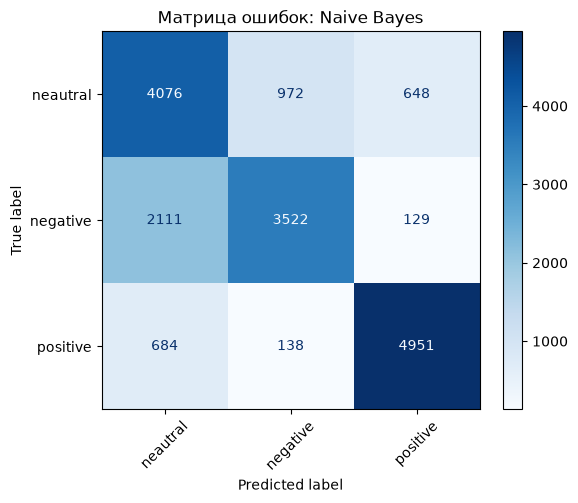

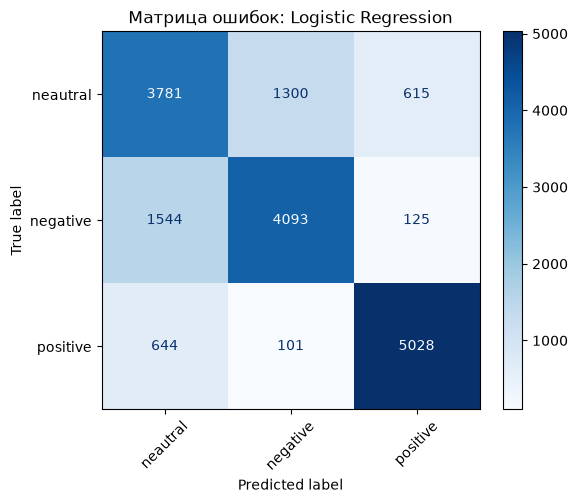

In [12]:
for name, y_pred in predictions.items():
    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        ax=ax,
        cmap="Blues",
        xticks_rotation=45
    )

    ax.set_title(f"Матрица ошибок: {name}")
    plt.tight_layout()
    plt.show()

In [13]:
errors = pd.DataFrame({
    "text": X_test,
    "true_label": y_test,
    "predicted_label": best_predictions
})

errors = errors[
    errors["true_label"] != errors["predicted_label"]
]

print("Всего ошибочных предсказаний:", len(errors))

display(errors[["text", "true_label", "predicted_label"]].head(5))

Всего ошибочных предсказаний: 4329


,text,true_label,predicted_label
50422,не понимаю почему хвалят эту рубашку осталась ...,neautral,negative
11561,отправили быстро пришло быстро заказала реале ...,negative,neautral
11783,брюки короткие рост см не хватает см длины брю...,negative,neautral
55336,товар не получила продавец деньги вернул,neautral,negative
55741,товар не пришел деньги вернули спасибо,neautral,negative


### Анализ пяти ошибок классификации

**1. Отзыв о рубашке**

Истинный класс: нейтральный. Предсказанный класс: негативный.

В тексте присутствует неодобрительная формулировка о рубашке. Модель могла воспринять её как отрицательную оценку, хотя исходная метка относится к нейтральному классу.

**2. Быстрая доставка и заказ**

Истинный класс: негативный. Предсказанный класс: нейтральный.

В отзыве упоминаются положительные обстоятельства, связанные с доставкой, которые могут затруднять определение общей тональности. Модель могла не учесть негативную оценку, выраженную в другой части полного текста.

**3. Короткие брюки**

Истинный класс: негативный. Предсказанный класс: нейтральный.

Отзыв содержит конкретную претензию к длине изделия. Модель могла не распознать эту претензию как выражение недовольства, поскольку текст не содержит ярких эмоциональных слов.

**4. Неполученный товар и возврат денег**

Истинный класс: нейтральный. Предсказанный класс: негативный.

Упоминание неполученного товара может восприниматься как негативный признак. При этом возврат денег снижает однозначность общей оценки ситуации.

**5. Неполученный товар и благодарность**

Истинный класс: нейтральный. Предсказанный класс: негативный.

В отзыве одновременно упоминается проблема с получением товара и присутствует благодарность за возврат денег. Модель могла придать больший вес негативным словам и недостаточно учесть положительную часть сообщения.

**Общий вывод:** ошибки возникают из-за неоднозначной тональности, сочетания положительных и отрицательных обстоятельств и ограничений модели при учёте контекста. TF-IDF представляет текст как набор признаков и не всегда позволяет правильно определить общий смысл отзыва.

In [14]:
display(results_df.round(4))

print("Лучшая модель:", best_model_name)
print(
    "Её Macro-F1:",
    round(
        results_df.loc[
            results_df["Model"] == best_model_name,
            "F1 (macro)"
        ].iloc[0],
        4
    )
)

print("Размерность TF-IDF:", X_train_tfidf.shape)
print("Количество классов:", y.nunique())
print("Ошибок на тестовой выборке:", len(errors))

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Naive Bayes,0.7283,0.7393,0.7281,0.7291
1,Logistic Regression,0.7488,0.7500,0.7484,0.7489


Лучшая модель: Logistic Regression
Её Macro-F1: 0.7489
Размерность TF-IDF: (68920, 10000)
Количество классов: 3
Ошибок на тестовой выборке: 4329
